# Exploratory Data Analysis on Retail Sales Data

## Oasis Infobyte Internship – Level 1 Task 1

### Author
Sinqobile Ntombela

### Objective
To perform Exploratory Data Analysis (EDA) on a retail sales dataset in order to identify trends, customer purchasing behaviour, and actionable business insights using Python.

### Tools
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

## Load the dataset

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
#Load Excel dataset
df = pd.read_excel("retail_sales_dataset.xlsx")

#Display the first 5 rows 
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


## Observations
* The dataset loaded successfully without error.
* The dataset has customer, product and transactions information.
* Each row is one purchase. 
* Columns include product information, quantity purchase, customer demographics and sales.
* The dataset contains 1000 rows and 9 columns.
* The dataset is large enough to perform EDA.
* The data is clean and ready for EDA.
* The average customer age is 4 years.
* Customers purchase average is 2.5 items per transactions.
* Customer ages range between 18 and 64 years.
* The average price per unit 179.89.
* The average transaction value is 456.
* Transaction values range from 25 to 2000, this indicates a wide variation in customer spending 
* The distribtion of customer ages is fairly even across the different age groups.
* No single age group dominates the customer base.
* The business attracts customers from a broad range of adult age groups.



## Understanding the dataset

In [5]:
# Displays the number of rows and columns
df.shape

(1000, 9)

In [6]:
# Displays the names of the columns
df.columns

Index(['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age',
       'Product Category', 'Quantity', 'Price per Unit', 'Total Amount'],
      dtype='str')

In [7]:
# Displays information about the dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction ID    1000 non-null   int64         
 1   Date              1000 non-null   datetime64[us]
 2   Customer ID       1000 non-null   str           
 3   Gender            1000 non-null   str           
 4   Age               1000 non-null   int64         
 5   Product Category  1000 non-null   str           
 6   Quantity          1000 non-null   int64         
 7   Price per Unit    1000 non-null   int64         
 8   Total Amount      1000 non-null   int64         
dtypes: datetime64[us](1), int64(5), str(3)
memory usage: 70.4 KB


## Descriptive Statistics

In [8]:
# Generates descriptive statstics
df.describe()

,Transaction ID,Date,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,2023-07-03 00:25:55.200000,41.39200,2.514000,179.890000,456.000000
min,1.000000,2023-01-01 00:00:00,18.00000,1.000000,25.000000,25.000000
25%,250.750000,2023-04-08 00:00:00,29.00000,1.000000,30.000000,60.000000
50%,500.500000,2023-06-29 12:00:00,42.00000,3.000000,50.000000,135.000000
75%,750.250000,2023-10-04 00:00:00,53.00000,4.000000,300.000000,900.000000
max,1000.000000,2024-01-01 00:00:00,64.00000,4.000000,500.000000,2000.000000
std,288.819436,NaN,13.68143,1.132734,189.681356,559.997632


## Customer Demographics Analysis

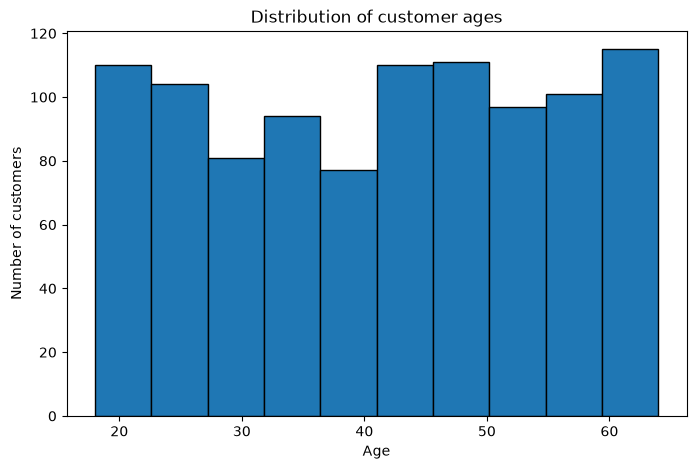

In [10]:
# Distribution of customer ages 
plt.figure(figsize = (8,5))
plt.hist(df["Age"], bins = 10, edgecolor = "black")

plt.title("Distribution of customer ages")
plt.xlabel("Age")
plt.ylabel("Number of customers")

plt.show()


In [ ]:
# Counts how many customers belong to each gender
df["Gender"].value_counts()

Gender
Female    510
Male      490
Name: count, dtype: int64

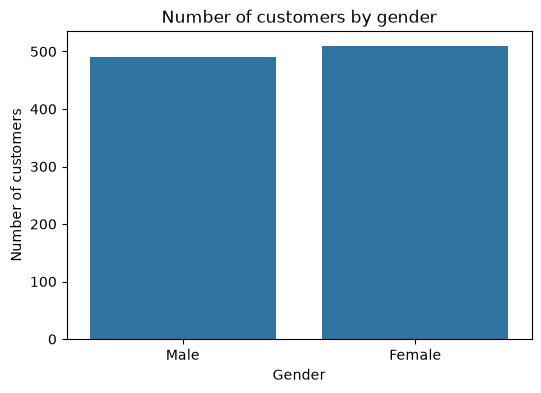

In [13]:
# Bar chart showing customer count by gender
plt.figure(figsize=(6,4))

sns.countplot(data=df, x="Gender")

plt.title("Number of customers by gender")
plt.xlabel("Gender")
plt.ylabel("Number of customers")

plt.show()

## Observations

* The chart shows the number of male and female customers.
* This helps determine whether the customer base is balanced across genders. * Understanding the gender distribution can support targeted marketing and product planning.
* The business attracts both genders fairly equally, so it doesn't appear to rely heavily on one gender for sales.

In [14]:
#Counts the number of transactions in each product category
df["Product Category"].value_counts()

Product Category
Clothing       351
Electronics    342
Beauty         307
Name: count, dtype: int64

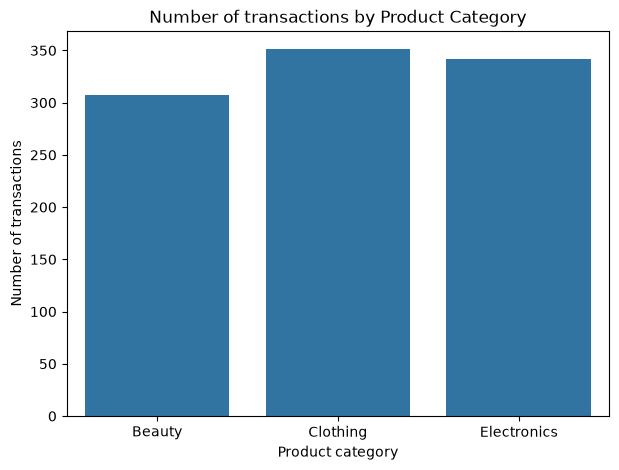

In [15]:
# Bar chart of product categories
plt.figure(figsize=(7,5))

sns.countplot(data=df, x="Product Category")

plt.title("Number of transactions by Product Category")
plt.xlabel("Product category")
plt.ylabel("Number of transactions")

plt.show()

## Observations

* Clothing has the highest number of transactions.
* Electronics is the second most purchased product category.
* Beauty has the lowest number of transactions.
* The differences between the three categories are small, indicating balanced customer demand across product categories.

In [16]:
# Total sales by product category
sales_by_category = df.groupby("Product Category")["Total Amount"].sum()

sales_by_category

Product Category
Beauty         143515
Clothing       155580
Electronics    156905
Name: Total Amount, dtype: int64

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 

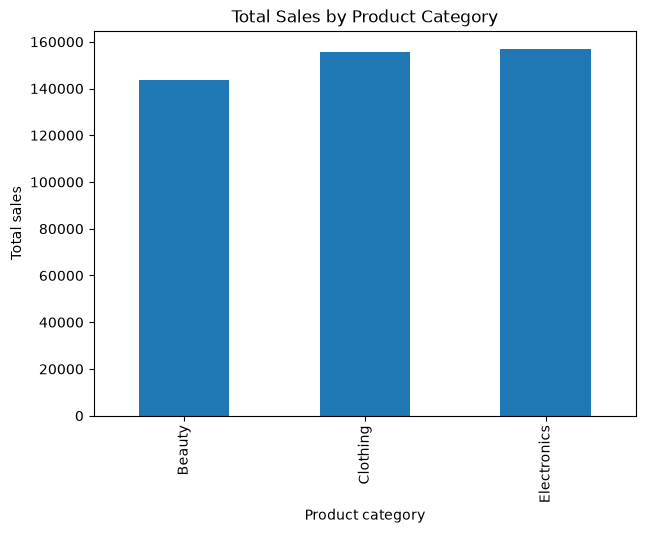

In [18]:
plt.figure(figsize=(7,5))

sales_by_category.plot(kind="bar")

plt.title("Total Sales by Product Category")
plt.xlabel("Product category")
plt.ylabel("Total sales")

plt.show()


## Observations

* Electronics generated the highest total sales revenue.
* Beauty generated the lowest total sales revenue.
* Although Clothing recorded the highest number of transactions, Electronics generated the most revenue.
* This suggests that Electronics products have a higher average selling price, resulting in greater revenue per transaction.

In [19]:
# Calculate monthly sales
monthly_sales = df.groupby(df["Date"].dt.to_period("M"))["Total Amount"].sum()

monthly_sales

Date
2023-01    35450
2023-02    44060
2023-03    28990
2023-04    33870
2023-05    53150
2023-06    36715
2023-07    35465
2023-08    36960
2023-09    23620
2023-10    46580
2023-11    34920
2023-12    44690
2024-01     1530
Freq: M, Name: Total Amount, dtype: int64

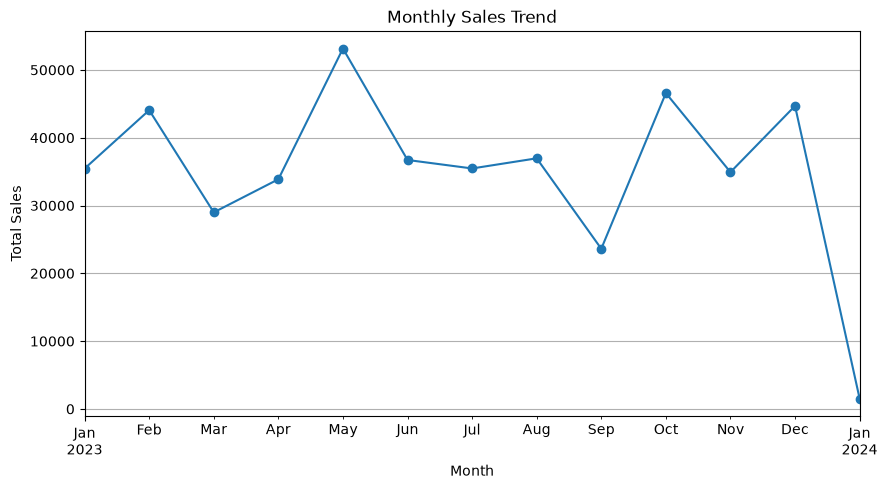

In [20]:
plt.figure(figsize=(10,5))

monthly_sales.plot(marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")

plt.grid(True)

plt.show()


## Observations

* Sales fluctuate throughout the year rather than following a consistent upward or downward trend.
* May recorded the highest monthly sales.
* January 2024 recorded the lowest monthly sales.
* The unusually low sales in January 2024 may be due to the dataset containing only a partial month's data rather than a full month's transactions.

In [21]:
# Correlation matrix for numerical columns
correlation = df.select_dtypes(include=["number"]).corr()

correlation

,Transaction ID,Age,Quantity,Price per Unit,Total Amount
Transaction ID,1.000000,0.065191,-0.026623,-0.060837,-0.075034
Age,0.065191,1.000000,-0.023737,-0.038423,-0.060568
Quantity,-0.026623,-0.023737,1.000000,0.017501,0.373707
Price per Unit,-0.060837,-0.038423,0.017501,1.000000,0.851925
Total Amount,-0.075034,-0.060568,0.373707,0.851925,1.000000


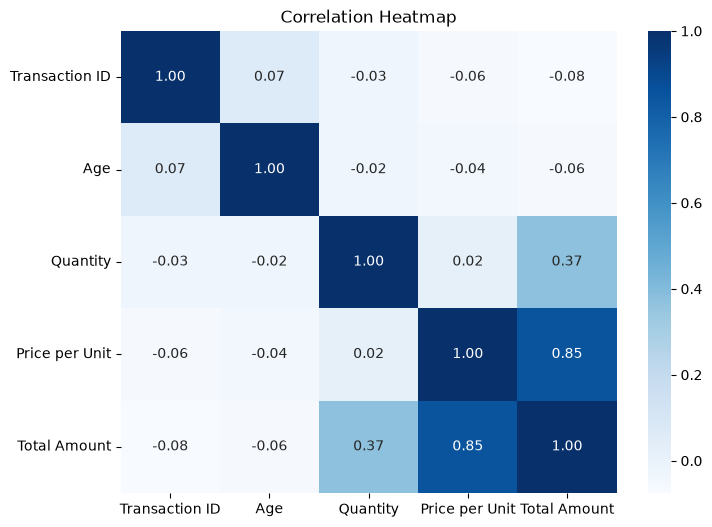

In [22]:
plt.figure(figsize=(8,6))

sns.heatmap(correlation, annot=True, cmap="Blues", fmt=".2f")

plt.title("Correlation Heatmap")

plt.show()

## Business Recommendations

Based on the exploratory data analysis, I recommend the following:

1. Focus marketing efforts on Electronics products, as they generated the highest total sales revenue.
2. Promote Beauty products through discounts or special offers to increase sales performance.
3. Monitor seasonal sales trends and prepare inventory for months with higher sales activity.
4. Since product price has the strongest relationship with total sales, the business should optimize pricing strategies while remaining competitive.
5. Continue collecting customer data to better understand purchasing behaviour and support future predictive analytics.

## Conclusion

This project explored a retail sales dataset using Python and various data analysis techniques.

The analysis included data exploration, descriptive statistics, customer demographics, product category analysis, sales trends over time, and correlation analysis.

The findings revealed that Electronics generated the highest revenue, while Beauty generated the lowest. Monthly sales fluctuated throughout the year, and Price per Unit showed the strongest positive correlation with Total Amount.

Overall, this exploratory data analysis provided valuable insights into customer behaviour and sales performance that can support better business decision-making.